# Регуляризация: Dropout и Batch Normalization

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 4. Глубокое обучение**

В этом файле рассматриваются два слоя, чьё поведение зависит от режима работы сети. Dropout временно обнуляет часть активаций при обучении. Batch Normalization преобразует промежуточные сигналы с учётом статистики и содержит собственное обучаемое и накопленное состояние.

Dropout применяется как метод регуляризации: сеть учится работать при случайном изменении доступных промежуточных сигналов. Batch Normalization прежде всего меняет условия обработки активаций и обучения; зависимость от состава пакета также может давать регуляризующий эффект. Его сила и польза зависят от задачи. Ни один из этих слоёв не гарантирует улучшения качества сам по себе.

Материал содержит выполненные примеры для занятия и самостоятельного чтения. **Заданий нет.** Перед каждым блоком кода дано введение, после него — разбор конструкций Python, методов и результата. Формулы и математические выводы не используются.

Примеры небольшие, выполняются на CPU и не скачивают данные или модели. Строение сетей, активации, градиенты, оптимизаторы и теория переобучения уже разобраны в предыдущих файлах. Здесь используем знакомые инструменты, сосредоточившись на новых слоях и режимах `train` и `eval`.

### Как читать и выполнять материал

Сохранённые таблицы и рисунки можно читать без запуска Python. Для повторного выполнения выберите **Restart Kernel and Run All / «Перезапустить ядро и выполнить все ячейки»**. Ядро хранит переменные и состояние моделей, поэтому ячейки связаны и выполняются сверху вниз.

Dropout использует случайность, а Batch Normalization в режиме обучения обновляет накопленное состояние даже без шага оптимизатора. Повтор отдельной ячейки может поэтому изменить опыт. Для возврата к исходному состоянию нужно повторить создание слоя или перезапустить весь ноутбук.

Нужны Python, PyTorch, NumPy, Pandas, Matplotlib, scikit-learn и среда Jupyter. Установка пакетов в коде не производится. Версии проверенной среды выведем ниже. Итоговое сравнение четырёх сетей демонстрационное: настройки заданы заранее, независимого финального тестирования здесь нет.

Подключим библиотеки и настроим выполнение на CPU в одном потоке. Для этой темы PyTorch позволяет видеть режимы отдельных слоёв, их параметры и накопленную статистику. Размеры примеров не требуют видеокарты или длительных вычислений.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch

from torch import nn
from IPython.display import display
from sklearn.datasets import make_moons
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.set_default_device('cpu')
torch.set_num_threads(1)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__)
print('scikit-learn:', sklearn.__version__)
print('Устройство примеров:', torch.get_default_device())

Python: 3.13.13
PyTorch: 2.11.0+xpu
NumPy: 2.4.6
Pandas: 2.3.3
Matplotlib: 3.10.9
scikit-learn: 1.8.0
Устройство примеров: cpu


**Разбор кода.**

- `import` подключает пакет или модуль. `as np`, `as pd`, `as plt` дают короткие имена. Точка в `matplotlib.pyplot` обозначает вложенный модуль; `from ... import ...` подключает отдельные инструменты. `nn` — модуль PyTorch с готовыми слоями и функциями потерь.
- NumPy работает с массивами, Pandas — с таблицами, Matplotlib — с рисунками. Scikit-learn создаёт учебные данные и помогает их подготовить и оценить. `display` показывает таблицы внутри ноутбука. Импорт не обучает модель.
- `torch.set_default_device('cpu')` выбирает CPU для создаваемых тензоров по умолчанию, `set_num_threads(1)` ограничивает вычислительные потоки в текущем процессе. `get_default_device()` читает устройство. Тензор — контейнер чисел PyTorch.
- `pd.set_option(...)` настраивает отображение таблиц, а не точность хранимых чисел. `plt.rcParams` содержит настройки рисунков. Квадратные скобки выбирают настройку по текстовому ключу, `=` присваивает значение. DejaVu Sans поддерживает кириллицу, `figure.dpi` задаёт плотность изображения.
- `print(...)` выводит текст и значения. `sys.version.split()[0]` разбивает строку сведений о Python по пробелам и берёт первый фрагмент. Позиции в Python считаются с нуля. `.__version__` — атрибут версии пакета.
- Точка выбирает атрибут или метод, круглые скобки выполняют вызов. Текст в кавычках — строка; числа без дробной части, например `1`, — целые значения.

## 1. Dropout: временное обнуление активаций

### Вероятность обнуления и сохранённый сигнал

В режиме обучения `Dropout` случайно выбирает элементы входного тензора и делает их нулевыми. В сети это обычно промежуточные активации. На следующем прямом проходе выбор делается заново. Веса и нейроны из архитектуры при этом не удаляются.

Параметр `p` — вероятность **обнулить** отдельный элемент. Например, `p=0.5` означает вероятность обнуления 50%, а не требование обнулить ровно половину конкретного короткого вектора. Сохранившиеся значения автоматически увеличиваются так, чтобы поддержать средний масштаб сигнала. При `p=0.5` они удваиваются.

Так сеть получает разные наборы доступных промежуточных сигналов и может меньше полагаться на отдельные их сочетания. Слишком сильное обнуление также может мешать обучению. Значение `p` выбирают по подходящей схеме проверки; правило «больше — всегда лучше» здесь не работает.

Применим Dropout дважды к одному вектору положительных значений. Зафиксируем случайное начальное состояние один раз перед серией вызовов. Поэтому серия воспроизводима при повторном полном выполнении, а внутри неё маски могут различаться.

In [2]:
torch.manual_seed(12)
signal_values = torch.arange(1, 9, dtype=torch.float32)
signal_snapshot = signal_values.clone()
dropout_layer = nn.Dropout(p=0.5)
dropout_layer.train()
dropout_first = dropout_layer(signal_values)
dropout_second = dropout_layer(signal_values)

display(pd.DataFrame({
    'Вход': signal_values.numpy(),
    'Первый проход': dropout_first.numpy(),
    'Второй проход': dropout_second.numpy(),
}))
print('Исходный тензор сохранился:', torch.equal(signal_values, signal_snapshot))
print('Обучаемые параметры Dropout:', list(dropout_layer.parameters()))

,Вход,Первый проход,Второй проход
0,1.0,0.0,0.0
1,2.0,0.0,4.0
2,3.0,6.0,6.0
3,4.0,8.0,8.0
4,5.0,0.0,0.0
5,6.0,0.0,12.0
6,7.0,0.0,0.0
7,8.0,16.0,16.0


Исходный тензор сохранился: True
Обучаемые параметры Dropout: []


**Разбор кода и результата.**

- `torch.manual_seed(12)` закрепляет случайное начальное состояние. `torch.arange(1, 9, dtype=torch.float32)` создаёт числа 1–8: правая граница не включается. `dtype` задаёт дробный тип значений. `.clone()` делает независимую копию для проверки.
- `nn.Dropout(p=0.5)` создаёт слой с вероятностью обнуления 0,5. Именованные аргументы записываются как `имя=значение`. `.train()` включает режим обучения; сам вызов не подбирает веса.
- `dropout_layer(signal_values)` выполняет прямой проход. Два вызова обращаются к одному слою и одному входу, но используют последовательные случайные выборы. Мы не возвращаем генератор в исходное состояние перед каждым проходом.
- `.numpy()` передаёт числа тензора CPU в таблицу. Здесь градиенты не запрашивались: исследуем готовые входные активации. `pd.DataFrame({...})` создаёт таблицу из словаря: ключи — названия столбцов, значения — их содержимое. `display(...)` показывает её.
- `torch.equal(...)` проверяет полное совпадение исходного тензора с копией. `.parameters()` перечисляет обучаемые параметры, `list(...)` собирает их в список, `print(...)` выводит результаты.

В строках видны нули и удвоенные входы. Стандартный `Dropout` не имеет собственных обучаемых весов; `p` задаётся человеком. По умолчанию вход не меняется на месте, поэтому исходный тензор сохранился. Обнуление относится к текущим активациям, а не к постоянному удалению соответствующих весов сети.

В сохранённом первом проходе остались три из восьми значений, во втором — пять. Например, вход 2 сначала обнулился, затем дал выход 4. Эти числа наглядно показывают, что вероятность 0,5 не означает ровно четыре сохранённых элемента в каждом проходе.

Изобразим восемь последовательных масок на том же положительном векторе. Тёмная клетка означает, что значение сохранилось в данном проходе; светлая — что оно обнулилось. Такой рисунок помогает увидеть, что одна позиция может сохраняться в одном проходе и исчезать в другом.

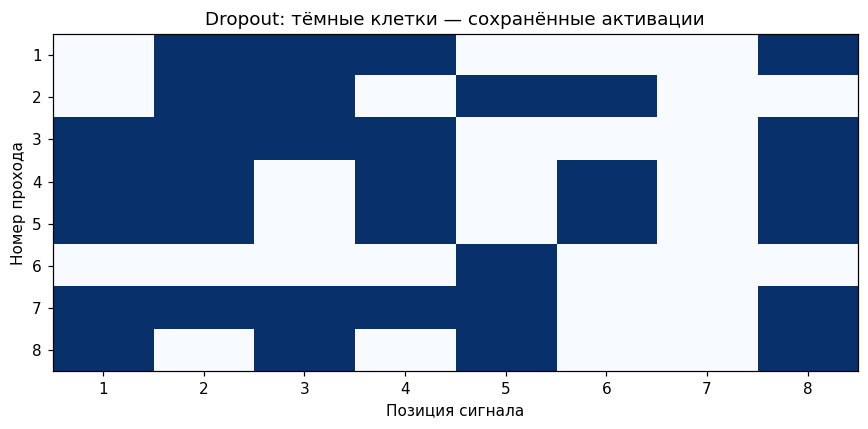

In [3]:
dropout_masks = torch.stack([dropout_layer(signal_values) != 0 for _ in range(8)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(dropout_masks.numpy(), cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(8), labels=range(1, 9))
ax.set_yticks(range(8), labels=range(1, 9))
ax.set_xlabel('Позиция сигнала')
ax.set_ylabel('Номер прохода')
ax.set_title('Dropout: тёмные клетки — сохранённые активации')
fig.tight_layout()
plt.show()

**Разбор кода и рисунка.**

- `[... for _ in range(8)]` — списковое включение: краткая запись цикла, создающего восемь результатов. `_` — обычное имя переменной; по соглашению его используют, когда сам номер не нужен. `range(8)` перебирает восемь позиций от 0 до 7.
- `dropout_layer(...) != 0` поэлементно проверяет, какие выходы не равны нулю. Исходные значения положительные, поэтому в этом опыте ноль однозначно означает обнуление Dropout. `torch.stack(...)` объединяет восемь логических векторов в таблицу формы `(8, 8)`.
- `plt.subplots(...)` создаёт рисунок и область. `imshow(...)` отображает таблицу цветом; `.numpy()` передаёт числа для рисования. `cmap` выбирает палитру, `vmin` и `vmax` закрепляют шкалу, `aspect='auto'` разрешает подстроить размеры клеток.
- `set_xticks` и `set_yticks` задают позиции и подписи делений: сами позиции начинаются с нуля, читаемые номера — с единицы. `set_xlabel`, `set_ylabel`, `set_title` задают подписи; `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

В каждой строке число сохранённых позиций может отличаться. На этом коротком векторе мы наблюдаем случайные маски, а не обязательное равенство их размеров. Одна и та же позиция не назначается «выключенной навсегда».

Проверим средний масштаб на большем, но всё ещё маленьком для компьютера наборе единиц. Для четырёх значений `p` посчитаем фактическую долю нулей и средний выход. Здесь всего 12 000 чисел на вариант; это локальная имитация, без загрузки данных.

In [4]:
torch.manual_seed(18)
unit_signals = torch.ones(1500, 8)
probability_rows = []
for probability in [0.0, 0.2, 0.5, 0.8]:
    layer = nn.Dropout(p=probability)
    layer.train()
    result = layer(unit_signals)
    probability_rows.append({
        'Заданное p': probability,
        'Фактическая доля нулей': (result == 0).float().mean().item(),
        'Средний вход': unit_signals.mean().item(),
        'Средний выход': result.mean().item(),
    })
display(pd.DataFrame(probability_rows).set_index('Заданное p'))

,Фактическая доля нулей,Средний вход,Средний выход
Заданное p,,,
0.0,0.0000,1.0,1.0000
0.2,0.1998,1.0,1.0003
0.5,0.4990,1.0,1.0020
0.8,0.8008,1.0,0.9958


**Разбор кода и результата.**

- `torch.manual_seed(...)` закрепляет серию. `torch.ones(1500, 8)` создаёт двумерный тензор единиц: 1500 строк и восемь значений в строке.
- Цикл `for probability in [...]` создаёт новый `nn.Dropout` для каждого `p`. `.train()` задаёт режим, `layer(...)` получает случайно преобразованный выход.
- `result == 0` создаёт логическую маску; `==` сравнивает, а `=` присваивает. `.float()` переводит логические значения в числа 0 и 1, `.mean()` усредняет все элементы. Поэтому получается доля обнулённых позиций. `.item()` извлекает одно число из одноэлементного тензора.
- `.mean()` на исходных и полученных значениях показывает их средний масштаб. `.append({...})` добавляет словарь строки в список. `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` собирают и показывают таблицу.

Фактическая доля нулей близка к заданному `p`, а средний выход — к единице. Сохранившиеся значения компенсируют обнулённые **в среднем**, а не обязаны сохранять точное среднее каждого короткого пакета. При `p=0` слой ничего не обнуляет.

### Проверка модели: Dropout перестаёт обнулять

В стандартном режиме `eval` Dropout передаёт сигнал без обнуления и без дополнительного масштабирования. Увеличение сохранённых значений уже учитывалось во время обучения. Поэтому для обычной проверки модели слой нужно переключить в `eval`, а не вручную умножать выходы или менять `p`.

Переключим тот же слой в режим проверки и дважды подадим прежний вход. Проверим совпадение с исходными значениями и прочитаем сохранённую настройку `p`: она остаётся прежней, а поведение меняется за счёт режима.

In [5]:
dropout_layer.eval()
eval_first = dropout_layer(signal_values)
eval_second = dropout_layer(signal_values)
display(pd.DataFrame({
    'Вход': signal_values.numpy(),
    'Первый проход eval': eval_first.numpy(),
    'Второй проход eval': eval_second.numpy(),
}))
print('Совпадает с исходным входом:', torch.equal(eval_first, signal_values))
print('Режим training:', dropout_layer.training)
print('Сохранённое p:', dropout_layer.p)

,Вход,Первый проход eval,Второй проход eval
0,1.0,1.0,1.0
1,2.0,2.0,2.0
2,3.0,3.0,3.0
3,4.0,4.0,4.0
4,5.0,5.0,5.0
5,6.0,6.0,6.0
6,7.0,7.0,7.0
7,8.0,8.0,8.0


Совпадает с исходным входом: True
Режим training: False
Сохранённое p: 0.5


**Разбор кода и результата.**

- `.eval()` переключает режим слоя. `dropout_layer(...)` теперь передаёт вход без случайного обнуления. Два вызова не требуют повторного обучения или изменения настройки.
- `.numpy()`, `pd.DataFrame(...)` и `display(...)` показывают числа. `torch.equal(...)` проверяет полное совпадение с входом.
- `.training` — логический атрибут режима; после `eval` он равен `False`. `.p` по-прежнему равно 0,5. `print(...)` выводит эти сведения.

Оба выхода совпали с исходным вектором. Вернуть обучающее поведение можно методом `train()`, не пересоздавая слой. При переключении режима всей сети соответствующее изменение передаётся вложенным слоям.

Отделим режим Dropout от записи градиентов. Сначала вызовем слой в `train` внутри `no_grad`, затем в `eval` с включённым учётом градиентов. В конце выполним демонстрационный обратный проход от суммы выхода, чтобы проверить доступность градиента по входу в режиме `eval`.

In [6]:
tracked_signal = signal_values.clone().requires_grad_(True)
dropout_layer.train()
with torch.no_grad():
    train_without_graph = dropout_layer(tracked_signal)

dropout_layer.eval()
eval_with_graph = dropout_layer(tracked_signal)
eval_with_graph.sum().backward()
display(pd.DataFrame({
    'Режим': ['train + no_grad', 'eval с учётом градиентов'],
    'Выход': [train_without_graph.tolist(), eval_with_graph.detach().tolist()],
    'requires_grad выхода': [train_without_graph.requires_grad, eval_with_graph.requires_grad],
}))
print('Градиент по входу в eval:', tracked_signal.grad.tolist())

,Режим,Выход,requires_grad выхода
0,train + no_grad,"[2.0, 4.0, 0.0, 0.0, 0.0, 12.0, 14.0, 0.0]",False
1,eval с учётом градиентов,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]",True


Градиент по входу в eval: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


**Разбор кода и результата.**

- `.clone()` создаёт отдельный вход, `.requires_grad_(True)` включает учёт градиентов относительно него. Завершающее подчёркивание в этом методе означает изменение настройки существующего тензора.
- После `.train()` блок `with torch.no_grad():` отключает запись новых операций в граф, но не переключает режим Dropout. Отступы определяют строки внутри блока. Вызов `dropout_layer(...)` продолжает применять случайное обнуление.
- После `.eval()` обнуление отключено, но учёт градиентов разрешён. `.sum()` делает одно число из выходов, `.backward()` вычисляет градиент по входу. Это демонстрация пути вычислений; у самого Dropout обучаемых параметров нет.
- `.tolist()` получает обычный список чисел для компактной строки, `.detach()` отделяет представление от графа для отчёта. `.requires_grad` показывает участие выхода в учёте градиентов. `.grad` хранит полученный градиент входа.
- `pd.DataFrame(...)`, `display(...)` и `print(...)` показывают различие двух состояний.

`no_grad` не выключил Dropout в `train`. Режим `eval` выключил случайность слоя, но не запретил вычислить градиенты. Это два отдельных управления; для обычной проверки сети далее используем `eval()` вместе с `no_grad()`.

## 2. Batch Normalization: преобразование с учётом пакета

### Текущий пакет и промежуточные признаки

Batch Normalization обрабатывает промежуточные значения сети по отдельным признакам или каналам. Для табличного примера возьмём вход формы «число объектов, число промежуточных признаков». В PyTorch с таким входом работает `BatchNorm1d`.

В режиме `train` слой использует расположение и разброс значений **текущего пакета** по каждому признаку. После этого применяются обучаемые масштаб и сдвиг. При начальных настройках они равны 1 и 0; при обучении сеть может изменить их.

Это преобразование находится внутри модели и повторяется для активаций, которые меняются по мере обучения предшествующих слоёв. Оно выполняет другую роль, чем подготовка исходных данных `StandardScaler`, разобранная ранее. При использовании Batch Normalization подготовка исходных признаков по-прежнему определяется задачей.

Состав пакета влияет на промежуточный результат и может вносить дополнительную изменчивость обучения. Это один из источников возможного регуляризующего эффекта. Также Batch Normalization может изменить удобство и скорость подбора параметров. Эти эффекты зависят от данных, архитектуры и настроек; гарантии улучшения нет.

Создадим пакет из четырёх объектов с двумя промежуточными признаками. Обработаем его новым BatchNorm1d в режиме обучения и посмотрим входы и выходы рядом. Настройки масштаба и сдвига пока начальные, поэтому сравниваем именно первичное преобразование пакета.

In [7]:
norm_inputs = torch.tensor([[10.0, 100.0], [12.0, 90.0], [14.0, 110.0], [16.0, 140.0]])
batchnorm_layer = nn.BatchNorm1d(2)
batchnorm_layer.train()
norm_outputs = batchnorm_layer(norm_inputs)
display(pd.DataFrame({
    'Вход: признак 1': norm_inputs[:, 0].numpy(),
    'Вход: признак 2': norm_inputs[:, 1].numpy(),
    'Выход: признак 1': norm_outputs[:, 0].detach().numpy(),
    'Выход: признак 2': norm_outputs[:, 1].detach().numpy(),
}))
print('Форма входа и выхода:', tuple(norm_inputs.shape), tuple(norm_outputs.shape))

,Вход: признак 1,Вход: признак 2,Выход: признак 1,Выход: признак 2
0,10.0,100.0,-1.3416,-0.5345
1,12.0,90.0,-0.4472,-1.0690
2,14.0,110.0,0.4472,0.0000
3,16.0,140.0,1.3416,1.6036


Форма входа и выхода: (4, 2) (4, 2)


**Разбор кода и результата.**

- `torch.tensor(...)` из вложенных списков создаёт таблицу формы `(4, 2)`: четыре объекта, два значения у каждого. `nn.BatchNorm1d(2)` задаёт число **признаков**, а не размер пакета. `.train()` включает обработку по текущему пакету.
- `batchnorm_layer(norm_inputs)` выполняет прямой проход. Слой содержит обучаемые параметры, поэтому его выход связан с графом даже при обычном входе без `requires_grad=True`.
- `[:, 0]` и `[:, 1]` выбирают все строки одного столбца. `.detach()` отделяет представление выходов от графа, `.numpy()` готовит числа для таблицы. Исходный вход не требует градиентов, поэтому его столбцы можно передать в NumPy непосредственно.
- `pd.DataFrame(...)` ставит входы и выходы рядом; `display(...)` показывает результат. `.shape` сообщает размерности, `tuple(...)` превращает их в обычный кортеж, `print(...)` выводит формы.

Оба столбца преобразованы отдельно: масштаб первого не используется как общий масштаб для второго. Форма данных сохранилась. При начальных параметрах результаты расположены около нуля; после обучения собственных масштаба и сдвига такое расположение уже не обязано сохраняться.

### Обучаемые параметры и буферы состояния

У Batch Normalization есть два разных вида сохраняемых чисел. **Параметры** масштаба и сдвига меняются через градиенты и оптимизатор. **Буферы** накопленной статистики обновляются прямыми проходами в режиме обучения, без `backward` и `step`.

При стандартном `track_running_stats=True` слой хранит сглаженные оценки среднего `running_mean` и разброса, дисперсии, `running_var`. Также хранится `num_batches_tracked` — счётчик обработанных в обучающем режиме пакетов. В `eval` используются накопленные оценки, а не статистика новых проверочных объектов.

Поэтому для воспроизведения работы такого слоя важны и параметры, и буферы. Только масштаб и сдвиг не описывают всё обученное состояние Batch Normalization.

Прочитаем два набора состояния слоя после предыдущего прямого прохода. Сначала выведем обучаемые параметры, затем буферы. Ничего дополнительно через слой не пропускаем, поэтому просмотр сам не меняет статистику.

In [8]:
parameter_rows = []
for name, parameter in batchnorm_layer.named_parameters():
    parameter_rows.append({
        'Имя': name,
        'Значения': str(parameter.detach().tolist()),
        'Требует градиент': parameter.requires_grad,
    })
buffer_rows = []
for name, buffer in batchnorm_layer.named_buffers():
    buffer_rows.append({
        'Имя': name,
        'Значения': str(buffer.tolist()),
        'Требует градиент': buffer.requires_grad,
    })
display(pd.DataFrame(parameter_rows).set_index('Имя'))
display(pd.DataFrame(buffer_rows).set_index('Имя'))

,Значения,Требует градиент
Имя,,
weight,"[1.0, 1.0]",True
bias,"[0.0, 0.0]",True


,Значения,Требует градиент
Имя,,
running_mean,"[1.3000000715255737, 11.0]",False
running_var,"[1.566666603088379, 47.56666564941406]",False
num_batches_tracked,1,False


**Разбор кода и состояния.**

- `.named_parameters()` перечисляет пары «имя, обучаемый параметр». Цикл `for name, parameter in ...` распаковывает пары; `.requires_grad` показывает запрос на вычисление градиентов.
- `.named_buffers()` отдельно перечисляет буферы. Здесь они не требуют градиентов, но остаются частью состояния слоя. Их просмотр не является новым прямым проходом.
- `.detach().tolist()` переводит числовое представление параметра в обычный список. У буфера достаточно `.tolist()`; у одноэлементного счётчика получается одно число. `str(...)` превращает результат в текст для компактного вывода.
- `.append({...})` добавляет словари в списки, `pd.DataFrame(...)`, `.set_index('Имя')` и `display(...)` показывают две таблицы.

`weight` содержит начальные масштабы `[1, 1]`, `bias` — начальные сдвиги `[0, 0]`. В предыдущем примере не было шага оптимизатора, поэтому они сохранились. Буферы уже учли один пакет: `num_batches_tracked` равен 1, а накопленные среднее и дисперсия изменились относительно начальных значений.

В выводе накопленное среднее первого признака хранится примерно как 1,30000007, а второго — 11. Длинная дробная запись связана с представлением чисел типа float32; для чтения здесь достаточно значений около 1,3 и 11. После одного пакета это ещё сглаженные оценки с влиянием начального состояния, а не просто средние текущих четырёх строк.

На отдельном слое явно зададим другой масштаб и сдвиг после первого преобразования. Это демонстрационная настройка, а не обучение оптимизатором. Оба раза используется один и тот же пакет в `train`, поэтому изменение результата можно связать с новыми обучаемыми числами.

In [9]:
affine_layer = nn.BatchNorm1d(2)
affine_layer.train()
with torch.no_grad():
    affine_before = affine_layer(norm_inputs)
    affine_layer.weight.copy_(torch.tensor([2.0, 0.5]))
    affine_layer.bias.copy_(torch.tensor([1.0, -1.0]))
    affine_after = affine_layer(norm_inputs)

display(pd.DataFrame({
    'Признак 1: до': affine_before[:, 0].numpy(),
    'Признак 1: после': affine_after[:, 0].numpy(),
    'Признак 2: до': affine_before[:, 1].numpy(),
    'Признак 2: после': affine_after[:, 1].numpy(),
}))

,Признак 1: до,Признак 1: после,Признак 2: до,Признак 2: после
0,-1.3416,-1.6833,-0.5345,-1.2673
1,-0.4472,0.1056,-1.0690,-1.5345
2,0.4472,1.8944,0.0000,-1.0000
3,1.3416,3.6833,1.6036,-0.1982


**Разбор кода и результата.**

- `nn.BatchNorm1d(2)` создаёт независимый слой, `.train()` задаёт режим. В блоке `torch.no_grad()` вычисления нужны для показа и ручной установки исходных настроек, поэтому новый граф не записывается.
- `affine_layer(norm_inputs)` получает первый результат. `.weight.copy_(...)` и `.bias.copy_(...)` копируют значения тензоров в существующие параметры. Подчёркивание означает изменение на месте. Мы сохраняем сами объекты параметров слоя, меняя их числа.
- `torch.tensor([2.0, 0.5])` задаёт отдельный масштаб для каждого признака, `[1.0, -1.0]` — отдельные сдвиги. Второй вызов `affine_layer(...)` использует новые значения.
- `[:, 0]`, `[:, 1]` выбирают столбцы. `.numpy()` передаёт результаты, вычисленные без графа, в `pd.DataFrame(...)`; `display(...)` показывает сравнение.

Первый признак растянут и сдвинут вверх, второй — сжат и сдвинут вниз. Значит, Batch Normalization не заставляет сеть навсегда выдавать только один фиксированный диапазон. В обычном обучении эти настройки подбираются совместно с остальными весами по общей потере.

### Как накапливается статистика

В стандартной настройке новые пакеты постепенно меняют накопленные оценки. Параметр `momentum` у Batch Normalization задаёт долю новой оценки в обновлённом состоянии. Например, при `momentum=0.1` новая оценка получает 10% влияния, прежнее состояние — 90%. При `momentum=1.0` накопленная оценка заменяется оценкой текущего пакета.

Это другой смысл слова `momentum`, чем память направления в оптимизаторе SGD из предыдущей темы. Настройка Batch Normalization управляет обновлением статистики и не является learning rate весов.

В режиме обучения выход использует текущий пакет, а в `eval` — накопленные оценки при включённом учёте статистики. Поэтому особенно в начале работы train- и eval-выходы могут заметно различаться. Накопленная дисперсия рассчитывается по правилу библиотеки, отличающемуся от оценки, применяемой при нормировании текущего пакета; точного совпадения режимов после одного пакета ожидать не нужно.

Сравним два новых слоя с разным `momentum` после обработки одного и того же пакета. Выведем первый нормированный результат и накопленные оценки первого признака. Так будет видно, что в `train` результат и обновление буферов имеют разные роли.

In [10]:
momentum_rows = []
for value in [0.1, 1.0]:
    layer = nn.BatchNorm1d(2, momentum=value)
    layer.train()
    with torch.no_grad():
        result = layer(norm_inputs)
    momentum_rows.append({
        'Momentum слоя': value,
        'Первый train-выход признака 1': result[0, 0].item(),
        'Накопленное среднее признака 1': layer.running_mean[0].item(),
        'Накопленная дисперсия признака 1': layer.running_var[0].item(),
        'Учтено пакетов': layer.num_batches_tracked.item(),
    })
display(pd.DataFrame(momentum_rows).set_index('Momentum слоя'))

,Первый train-выход признака 1,Накопленное среднее признака 1,Накопленная дисперсия признака 1,Учтено пакетов
Momentum слоя,,,,
0.1,-1.3416,1.3,1.5667,1
1.0,-1.3416,13.0,6.6667,1


**Разбор кода и результата.**

- Цикл создаёт два независимых `nn.BatchNorm1d` с разным `momentum`. Остальные настройки, вход и начальные параметры одинаковы. `.train()` включает обработку по текущему пакету.
- `torch.no_grad()` выключает запись графа, но прямой вызов `layer(...)` всё равно обновляет буферы режима обучения. `result[0, 0]` выбирает значение первого объекта и первого признака.
- `.running_mean[0]` и `.running_var[0]` читают накопленное состояние первого признака, `.num_batches_tracked` — счётчик. `.item()` извлекает одиночные числа.
- `.append({...})`, `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` формируют таблицу.

Train-выход первого признака совпадает, потому что используется один текущий пакет. Накопленные оценки различаются из-за разных долей обновления. Это не два разных результата обучения весов: `backward` и `step` здесь отсутствуют.

У обоих слоёв первый train-выход около −1,3416. При momentum=0,1 накопленное среднее первого признака равно примерно 1,3, при momentum=1,0 — 13. Значение 13 соответствует среднему текущего пакета; изменение momentum повлияло на сохранённое состояние, а не на использованный train-выход этого пакета.

## 3. Состав пакета и режим работы Batch Normalization

### Один объект рядом с разными соседями

В `train` промежуточный ответ объекта может измениться, если рядом с ним в пакет попадут другие объекты. Именно поэтому размер и состав пакетов имеют значение. В обычном `eval` с накопленной статистикой такой зависимости для Batch Normalization нет: каждый новый объект использует одни и те же сохранённые оценки.

Поставим объект с признаками 10 и 100 в начало двух пакетов. В одном рядом будут близкие значения, в другом — заметно более крупные. Пропустим оба пакета через отдельный слой в `train` и сравним только первую строку.

In [11]:
near_batch = torch.tensor([[10.0, 100.0], [11.0, 90.0], [9.0, 110.0], [10.0, 100.0]])
far_batch = torch.tensor([[10.0, 100.0], [30.0, 300.0], [40.0, 400.0], [50.0, 500.0]])
context_layer = nn.BatchNorm1d(2)
context_layer.train()
with torch.no_grad():
    near_train_output = context_layer(near_batch)[0]
    far_train_output = context_layer(far_batch)[0]
display(pd.DataFrame(
    torch.stack([near_train_output, far_train_output]).numpy(),
    index=['Рядом близкие значения', 'Рядом более крупные значения'],
    columns=['Выход признака 1', 'Выход признака 2'],
))

,Выход признака 1,Выход признака 2
Рядом близкие значения,0.0000,0.0000
Рядом более крупные значения,-1.5213,-1.5213


**Разбор кода и результата.**

- Два `torch.tensor(...)` создают пакеты одинаковой формы `(4, 2)`. Их первая строка совпадает; остальные строки различаются.
- `nn.BatchNorm1d(2)` создаёт слой со стандартными масштабом и сдвигом. В `.train()` он использует текущую статистику каждого пакета. Новые настройки накопленного состояния не подменяют её при втором train-вызове.
- В блоке `torch.no_grad()` два вызова `context_layer(...)` получают выходы. `[0]` выбирает первую строку из каждого. `torch.stack(...)` объединяет две строки для сравнения.
- `.numpy()` передаёт числа, `pd.DataFrame(..., index=..., columns=...)` даёт названия строкам и столбцам, `display(...)` выводит таблицу.

Исходный объект не менялся, а его преобразованный ответ изменился из-за соседей. Это свойство пакетной обработки в `train`. Оно не означает, что модель получила разные правильные ответы или что в данном опыте оптимизатор менял веса.

В выполненном опыте первая строка получила значения около 0 и 0 рядом с близкими соседями и около −1,5213 по обоим признакам рядом с более крупными. Так пакетная статистика меняет положение одного и того же исходного объекта.

Переключим тот же слой в `eval` и повторим сравнение. Дополнительно подадим первый объект отдельно, одной строкой. Все вызовы будут использовать одни накопленные оценки, полученные до переключения режима.

In [12]:
context_layer.eval()
with torch.no_grad():
    near_eval_output = context_layer(near_batch)[0]
    far_eval_output = context_layer(far_batch)[0]
    alone_eval_output = context_layer(near_batch[:1])[0]
display(pd.DataFrame(
    torch.stack([near_eval_output, far_eval_output, alone_eval_output]).numpy(),
    index=['Рядом близкие значения', 'Рядом более крупные значения', 'Объект подан отдельно'],
    columns=['Выход признака 1', 'Выход признака 2'],
))
print('Ответы близки во всех трёх случаях:', torch.allclose(near_eval_output, far_eval_output) and torch.allclose(near_eval_output, alone_eval_output))

,Выход признака 1,Выход признака 2
Рядом близкие значения,1.0674,1.0819
Рядом более крупные значения,1.0674,1.0819
Объект подан отдельно,1.0674,1.0819


Ответы близки во всех трёх случаях: True


**Разбор кода и результата.**

- `.eval()` переключает использование статистики. В `torch.no_grad()` слой `context_layer(...)` трижды читает накопленное состояние и не обновляет его.
- `near_batch[:1]` сохраняет таблицу с одной строкой. Следующий `[0]` выбирает первую строку **выхода** для общего формата таблицы. `torch.stack`, `.numpy()`, `pd.DataFrame` и `display` собирают сравнение.
- `torch.allclose(...)` проверяет близость чисел с учётом небольших вычислительных погрешностей. `and` означает логическое «и» двух проверок; `print(...)` выводит общий результат.

Ответ первой строки совпадает с точностью вычислений независимо от соседей. Числа не обязаны быть близкими к нулю: накопленные оценки пока получили только два условных пакета, полноценное обучение здесь не оценивалось.

Для табличного входа формы `(число объектов, число признаков)` BatchNorm1d в `train` требует более одной строки: по одному значению на признак недостаточно для этой обработки, и PyTorch сообщает ошибку. В `eval` с накопленными оценками одна строка допустима, что и показано. Намеренно ошибочный train-вызов на одной строке не выполняем.

На новом слое отдельно проверим прямой проход `train + no_grad`. Сравним до и после накопленное среднее и масштаб. Это важный случай: отключение градиентов не защищает накопленную статистику от изменения, если слой оставлен в режиме обучения.

In [13]:
state_layer = nn.BatchNorm1d(2)
mean_before = state_layer.running_mean.clone()
weight_before = state_layer.weight.detach().clone()
state_layer.train()
with torch.no_grad():
    state_output = state_layer(norm_inputs)

print('Выход требует градиентов:', state_output.requires_grad)
print('Накопленное среднее сохранилось:', torch.equal(mean_before, state_layer.running_mean))
print('Обучаемый масштаб сохранился:', torch.equal(weight_before, state_layer.weight.detach()))
print('Учтено пакетов:', state_layer.num_batches_tracked.item())

Выход требует градиентов: False
Накопленное среднее сохранилось: False
Обучаемый масштаб сохранился: True
Учтено пакетов: 1


**Разбор кода и результата.**

- `nn.BatchNorm1d(2)` создаёт независимый слой. `.running_mean.clone()` делает копию буфера, `.weight.detach().clone()` — независимую числовую копию обучаемого масштаба. Один `detach` мог бы разделять память с параметром, поэтому для снимка нужна также копия.
- `.train()` включает обучающее поведение. Блок `torch.no_grad()` отключает создание нового графа, но вызов `state_layer(...)` продолжает обновление статистики.
- `.requires_grad` у выхода показывает отсутствие записи для градиентов. `torch.equal(...)` отдельно сравнивает буфер и параметр с их копиями. `.num_batches_tracked.item()` читает число учтённых пакетов, `print(...)` выводит результаты.

Среднее изменилось, а обучаемый масштаб сохранился. Статистика меняется прямым проходом, параметры масштаба и сдвига — через обычное обучение оптимизатором. Поэтому при валидации одной команды `no_grad` недостаточно: нужен ещё режим `eval`.

### Когда `eval` тоже использует пакет

В предыдущих примерах действовала стандартная настройка `track_running_stats=True`. Если отключить её, накопленных среднего и дисперсии не будет. Тогда Batch Normalization использует статистику текущего пакета и при обучении, и при проверке. Режим `eval` сам по себе не создаёт отсутствующие буферы.

Явно создадим слой без накопления статистики и включим `eval`. Повторим опыт с тем же объектом и разными соседями. Этот вариант нужен для понимания настройки; в дальнейшем сравнении сетей будем использовать стандартное накопление статистики.

In [14]:
untracked_layer = nn.BatchNorm1d(2, track_running_stats=False)
untracked_layer.eval()
with torch.no_grad():
    untracked_near = untracked_layer(near_batch)[0]
    untracked_far = untracked_layer(far_batch)[0]
display(pd.DataFrame(
    torch.stack([untracked_near, untracked_far]).numpy(),
    index=['Рядом близкие значения', 'Рядом более крупные значения'],
    columns=['Выход признака 1', 'Выход признака 2'],
))
print('Накопленное среднее:', untracked_layer.running_mean)
print('Накопленная дисперсия:', untracked_layer.running_var)
print('Ответы близки:', torch.allclose(untracked_near, untracked_far))

,Выход признака 1,Выход признака 2
Рядом близкие значения,0.0000,0.0000
Рядом более крупные значения,-1.5213,-1.5213


Накопленное среднее: None
Накопленная дисперсия: None
Ответы близки: False


**Разбор кода и результата.**

- `nn.BatchNorm1d(2, track_running_stats=False)` отключает создание и обновление накопленных оценок. Логическое значение `False` означает «нет». `.eval()` переключает режим, но слой всё равно вынужден использовать текущий пакет.
- В `torch.no_grad()` вызовы `untracked_layer(...)` обрабатывают два пакета. `[0]` выбирает одинаковый по исходным значениям первый объект.
- `torch.stack`, `.numpy()`, `pd.DataFrame`, `display` показывают результаты. `.running_mean` и `.running_var` равны `None`, то есть накопленные значения отсутствуют. `torch.allclose(...)` сравнивает ответы, `print(...)` выводит состояние.

Ответы различаются даже в `eval`. Поэтому утверждение о независимости проверочного объекта от соседей относится к рассмотренной стандартной конфигурации с сохранённой статистикой. Для варианта без неё сохраняется и требование достаточного числа наблюдений на признак; одну строку в этом примере не подаём.

## 4. Сравнение четырёх сетей на одной задаче

### Что фиксируем до сравнения

Возьмём две шумные изогнутые группы с известными классами. На одной обучающей части создадим четыре варианта: без дополнительных слоёв, с Dropout, с Batch Normalization и с обоими механизмами. Во всех вариантах два скрытых линейных слоя по 24 нейрона, одинаковая активация ReLU и один бинарный логит на выходе.

Используем 120 эпох, пакеты по 18 объектов и Adam с `lr=0.01`. Число эпох, настройка Dropout `p=0.3` и стандартное накопление статистики Batch Normalization заданы заранее. Архитектуры и код оптимизатора здесь не рассматриваются заново: они нужны как общий контекст для сравнения новых слоёв.

Подготовка изучает только обучающие признаки. Потери **на обучающих объектах и на валидации в отчёте** будут считаться в режиме `eval`. Так сравниваем работу обученных сетей при выключенном Dropout и фиксированной статистике. Потеря, по которой шёл конкретный случайный обучающий шаг, могла иметь другое значение.

Создадим 240 объектов и выделим 72 для обучения, остальные 168 — для валидации. Небольшая обучающая часть сделает различия поведения заметнее, но результат останется только учебной иллюстрацией. Подготовим тензоры, сохраняя отдельные признаки и ответы.

In [15]:
class_values, class_labels = make_moons(n_samples=240, noise=0.25, random_state=22)
X_train, X_valid, y_train, y_valid = train_test_split(
    class_values, class_labels, train_size=0.3, stratify=class_labels, random_state=15
)
scaler = StandardScaler()
train_features = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)
valid_features = torch.tensor(scaler.transform(X_valid), dtype=torch.float32)
train_targets = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
valid_targets = torch.tensor(y_valid, dtype=torch.float32).reshape(-1, 1)

print('Обучающие признаки и цели:', tuple(train_features.shape), tuple(train_targets.shape))
print('Валидационные признаки и цели:', tuple(valid_features.shape), tuple(valid_targets.shape))
print('Обучающих пакетов по 18 объектов за эпоху:', len(train_features) // 18)

Обучающие признаки и цели: (72, 2) (72, 1)
Валидационные признаки и цели: (168, 2) (168, 1)
Обучающих пакетов по 18 объектов за эпоху: 4


**Разбор кода и данных.**

- `make_moons(...)` создаёт признаки и ответы: `n_samples` задаёт число объектов, `noise` — разброс, `random_state` — воспроизводимость. `train_test_split(...)` согласованно делит их. `train_size=0.3` выделяет 30% в обучение, `stratify=class_labels` сохраняет примерно одинаковые доли классов, второй `random_state` закрепляет разбиение.
- `StandardScaler()` создаёт подготовку. `fit_transform(X_train)` изучает её и преобразует обучение, `transform(X_valid)` применяет уже сохранённое правило к валидации. Нормализация внутри сети будет работать дополнительно с промежуточными сигналами.
- `torch.tensor(..., dtype=torch.float32)` создаёт тензоры дробного типа. `.reshape(-1, 1)` задаёт один столбец целей: число строк определяется автоматически вместо `-1`. Формы согласованы с одним бинарным логитом и `BCEWithLogitsLoss`.
- `.shape`, `tuple(...)` и `print(...)` показывают размерности. `len(...)` считает обучающие строки, `// 18` выполняет целочисленное деление для подсчёта полных пакетов.

Каждая эпоха содержит четыре пакета по 18 объектов, все они больше одной строки. В данном наборе остаточного пакета нет. При другой организации данных размер последнего пакета проверяют отдельно, особенно при использовании Batch Normalization.

Подготовим функцию создания четырёх конфигураций. В вариантах с Batch Normalization он будет стоять после скрытого линейного слоя и до ReLU. Dropout, когда включён, будет стоять после ReLU. Покажем структуру одного ещё не обученного варианта с обоими слоями.

In [16]:
def build_model(dropout_probability=0.0, use_batchnorm=False):
    layers = [nn.Linear(2, 24)]
    if use_batchnorm:
        layers.append(nn.BatchNorm1d(24))
    layers.append(nn.ReLU())
    if dropout_probability > 0:
        layers.append(nn.Dropout(dropout_probability))
    layers.append(nn.Linear(24, 24))
    if use_batchnorm:
        layers.append(nn.BatchNorm1d(24))
    layers.append(nn.ReLU())
    if dropout_probability > 0:
        layers.append(nn.Dropout(dropout_probability))
    layers.append(nn.Linear(24, 1))
    return nn.Sequential(*layers)

configurations = {
    'Без дополнительных слоёв': (0.0, False),
    'Dropout': (0.3, False),
    'Batch Normalization': (0.0, True),
    'Dropout + Batch Normalization': (0.3, True),
}
layout_example = build_model(dropout_probability=0.3, use_batchnorm=True)
print(layout_example)

Sequential(
  (0): Linear(in_features=2, out_features=24, bias=True)
  (1): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=24, out_features=24, bias=True)
  (5): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=24, out_features=1, bias=True)
)


**Разбор кода и структуры.**

- `def build_model(...)` задаёт функцию. Значения по умолчанию означают отсутствие обоих дополнительных слоёв. `layers` — список объектов, начиная с `nn.Linear(2, 24)`.
- `if use_batchnorm:` добавляет `nn.BatchNorm1d(24)`, когда условие истинно. Число 24 относится к **выходам скрытого слоя**, а не к двум исходным признакам. `.append(...)` дописывает объект в конец списка.
- `nn.ReLU()` задаёт знакомую активацию. Проверка `dropout_probability > 0` добавляет `nn.Dropout(...)` только при ненулевой настройке. Далее строится второй скрытый переход и выходной `nn.Linear(24, 1)`.
- `return nn.Sequential(*layers)` возвращает последовательность. Звёздочка `*` раскрывает список слоёв в отдельные аргументы конструктора. Порядок в списке определяет прямой проход.
- `configurations` — словарь названий и кортежей из двух настроек. `True` означает включённую Batch Normalization, `False` — выключенную. `build_model(...)` создаёт пример структуры, `print(...)` выводит её без обучения.

В выводе видны позиции слоёв и их настройки. У BatchNorm1d стандартные `affine=True` и `track_running_stats=True` означают наличие обучаемых масштаба и сдвига и накопление статистики. `eps` — маленькая добавка для численной устойчивости при малом разбросе; в примерах оставляем стандартное значение. Ни sigmoid на выходе, ни дополнительные регуляризующие штрафы здесь не добавляются: используется потеря по логитам из предыдущей темы.

Соберём обучение одного варианта в функцию. Перед созданием каждой сети будем фиксировать начальное случайное состояние. Для порядка строк создадим отдельный генератор: тогда случайные маски Dropout не изменят последовательность обучающих пакетов между конфигурациями. Валидационные проходы обязательно будут в `eval` и `no_grad`.

In [17]:
def train_variant(dropout_probability, use_batchnorm, epochs=120, batch_size=18):
    torch.manual_seed(50)
    model = build_model(dropout_probability, use_batchnorm)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.BCEWithLogitsLoss()
    order_generator = torch.Generator(device='cpu').manual_seed(73)
    rows = []

    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(train_features), generator=order_generator)
        for start in range(0, len(train_features), batch_size):
            positions = order[start:start + batch_size]
            batch_features = train_features[positions]
            batch_targets = train_targets[positions]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(batch_features), batch_targets)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            training_loss = criterion(model(train_features), train_targets).item()
            validation_loss = criterion(model(valid_features), valid_targets).item()
        rows.append({
            'Эпоха': epoch,
            'Потеря обучения в eval': training_loss,
            'Потеря валидации в eval': validation_loss,
        })
    return model, pd.DataFrame(rows).set_index('Эпоха')

print('Функция обучения и проверки одного варианта подготовлена.')

Функция обучения и проверки одного варианта подготовлена.


**Разбор кода и режимов.**

- `def train_variant(...)` задаёт настройки дополнительных слоёв, число эпох и размер пакета. `torch.manual_seed(50)` закрепляет исходную случайность перед `build_model(...)`. `torch.optim.Adam(model.parameters(), lr=0.01)` создаёт один оптимизатор на всё обучение. `nn.BCEWithLogitsLoss()` создаёт знакомую потерю по бинарным логитам.
- `torch.Generator(device='cpu').manual_seed(73)` создаёт отдельный генератор для порядка объектов. `torch.randperm(len(train_features), generator=...)` выдаёт случайную перестановку позиций с помощью именно этого генератора.
- Внешний `for epoch in range(1, epochs + 1)` перебирает эпохи. `model.train()` включает обучающее поведение всех вложенных Dropout и BatchNorm. Внутренний `range(0, ..., batch_size)` перебирает начала пакетов. Срез `order[start:start + batch_size]` выбирает позиции, а квадратные скобки у тензоров — признаки и цели этих объектов.
- `zero_grad(set_to_none=True)`, вычисление `criterion(model(...), ...)`, `backward()` и `step()` выполняют изученный шаг обучения. Batch Normalization обновляет статистику при прямом проходе; Dropout создаёт маски. Обратный проход и оптимизатор отдельно подбирают обучаемые параметры.
- После эпохи `model.eval()` выключает Dropout и переводит стандартную Batch Normalization на сохранённые оценки. В `torch.no_grad()` два контрольных прямых прохода не строят граф и не обновляют статистику. `.item()` получает числа потерь.
- `.append({...})` добавляет отчёт. `return model, ...` возвращает два результата: обученную модель и `pd.DataFrame(...)` истории с `.set_index('Эпоха')`. `print(...)` сообщает о готовности функции; само определение ещё не запускает обучение.

Потери обеих частей в истории посчитаны в одинаковом режиме. Перед следующей эпохой внешний цикл снова включает `train`. После последней проверки функция возвращает сеть, оставшуюся в `eval`.

Обучим все четыре заранее выбранных варианта. В итоговой таблице покажем потери, F1 и число обучаемых параметров. Эти числа относятся к одной фиксированной разбивке; конфигурации не меняются после просмотра результатов.

In [18]:
trained_models = {}
training_histories = {}
comparison_rows = []
for name, (probability, use_batchnorm) in configurations.items():
    model, history = train_variant(probability, use_batchnorm)
    trained_models[name] = model
    training_histories[name] = history
    with torch.no_grad():
        training_predictions = (torch.sigmoid(model(train_features)).squeeze(1).numpy() >= 0.5).astype(int)
        validation_predictions = (torch.sigmoid(model(valid_features)).squeeze(1).numpy() >= 0.5).astype(int)
    comparison_rows.append({
        'Вариант': name,
        'Параметров': sum(parameter.numel() for parameter in model.parameters()),
        'Потеря обучения (eval)': history.iloc[-1]['Потеря обучения в eval'],
        'Потеря валидации (eval)': history.iloc[-1]['Потеря валидации в eval'],
        'F1 обучения': f1_score(y_train, training_predictions, zero_division=0),
        'F1 валидации': f1_score(y_valid, validation_predictions, zero_division=0),
    })
comparison = pd.DataFrame(comparison_rows).set_index('Вариант')
display(comparison)

,Параметров,Потеря обучения (eval),Потеря валидации (eval),F1 обучения,F1 валидации
Вариант,,,,,
Без дополнительных слоёв,697,0.0268,0.7469,1.0000,0.8715
Dropout,697,0.1187,0.3010,0.9315,0.9000
Batch Normalization,793,0.1392,0.2221,0.9600,0.9061
Dropout + Batch Normalization,793,0.1710,0.2138,0.9189,0.9121


**Разбор кода и результата.**

- Два пустых словаря сохраняют модели и истории. `.items()` выдаёт название и пару настроек; запись `for name, (probability, use_batchnorm)` распаковывает вложенный кортеж. `train_variant(...)` запускает обучение, два результата распределяются по `model, history`.
- Сети возвращены в `eval`. В `torch.no_grad()` вызов `model(...)` получает логиты, `torch.sigmoid(...)` — оценки класса 1. `squeeze(1)` убирает единичный столбец, `.numpy()` передаёт числа. `>= 0.5` сравнивает их с фиксированным порогом, `.astype(int)` создаёт коды 0 и 1.
- `.parameters()` перечисляет обучаемые тензоры, `.numel()` считает их числа, `sum(... for ... in ...)` получает общее количество. Буферы статистики в это число не входят. Dropout параметров не добавляет, Batch Normalization добавляет масштабы и сдвиги.
- `.iloc[-1]` выбирает последнюю строку истории по позиции, последующие скобки — столбец по имени. `f1_score(..., zero_division=0)` считает знакомую F1 класса 1. `.append({...})` накапливает строки, `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` показывают итог.

Более высокая потеря на обучающих объектах не обязательно означает менее полезную модель на новых данных. Здесь важно сопоставлять обе части и назначение методов. Сравнение небольшое, при конкретных настройках; оно не даёт общего рейтинга Dropout и Batch Normalization и не заменяет независимое финальное тестирование.

В сохранённом результате сеть без дополнительных слоёв получила F1 обучения 1 и учебную потерю около 0,0268, но валидационную потерю около 0,7469. У Dropout учебная потеря выше — около 0,1187, зато валидационная ниже — около 0,3010. У Batch Normalization валидационная потеря около 0,2221, у совместного варианта — около 0,2138. Валидационная F1 совместного варианта около 0,9121 против 0,8715 у исходной сети. Это конкретный пример полезного изменения поведения на проверочных объектах при менее точной подстройке под обучение.

Посмотрим историю потерь каждого варианта, сохраняя одинаковые определения train- и validation-оценок в `eval`. Панели показывают процесс при заранее заданных 120 эпохах. По графику не будем задним числом выбирать самую красивую эпоху или объявлять её независимой финальной проверкой.

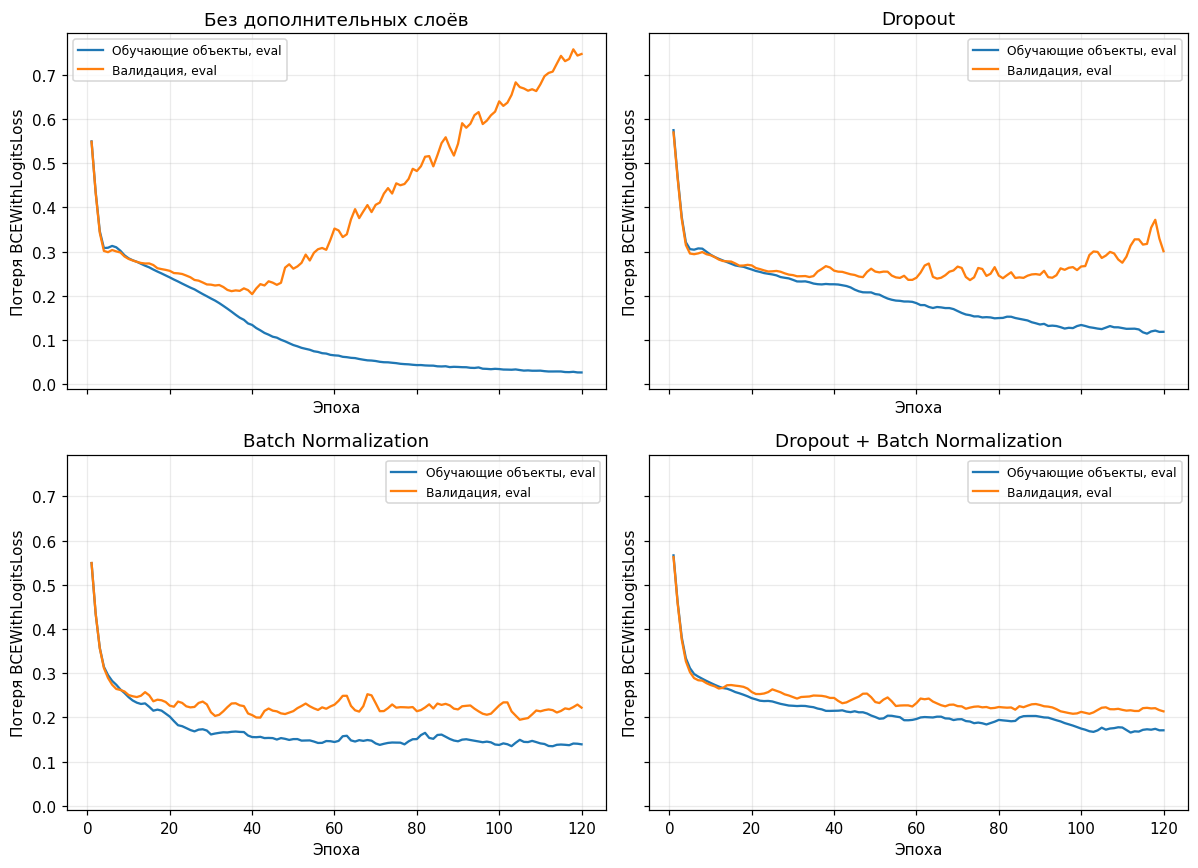

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (name, history) in zip(axes.flat, training_histories.items()):
    ax.plot(history.index, history['Потеря обучения в eval'], label='Обучающие объекты, eval')
    ax.plot(history.index, history['Потеря валидации в eval'], label='Валидация, eval')
    ax.set_title(name)
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Потеря BCEWithLogitsLoss')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Разбор кода и рисунка.**

- `plt.subplots(2, 2, ..., sharex=True, sharey=True)` создаёт четыре области с общими масштабами обеих осей. `axes.flat` последовательно перебирает их; `zip(...)` сопоставляет каждую с парой названия и истории из `.items()`.
- Вложенная распаковка `ax, (name, history)` получает область, название и таблицу. `.index` содержит номера эпох, квадратные скобки выбирают столбцы. Два `plot(...)` рисуют учебную и валидационную линии.
- `set_title`, `set_xlabel`, `set_ylabel` задают подписи; `grid(alpha=0.25)` добавляет полупрозрачную сетку, `legend(fontsize=8)` — легенду. `tight_layout()` размещает панели, `plt.show()` выводит результат.

Различия линий относятся к работе обученных состояний в режиме проверки. Учебный forward с активными случайными масками в эту историю напрямую не записывался. Панели помогают увидеть, почему уменьшение только обучающей потери не является достаточным основанием для выбора модели.

## 5. Проверка обученного состояния

В следующем просмотре используем вариант с обоими слоями как удобный пример их совместной работы. Он выбран для демонстрации состояния по устройству, а не как автоматически лучший вариант из таблицы. Уже обученную сеть заново обучать не будем.

Прочитаем режимы вложенных Dropout и BatchNorm у обученной сети. У BatchNorm также покажем счётчик учтённых пакетов. Такой просмотр подтверждает, что проверка оставила все эти слои в `eval`, а обучающие проходы ранее накопили своё состояние.

In [20]:
combined_model = trained_models['Dropout + Batch Normalization']
combined_model.eval()
mode_rows = []
for name, module in combined_model.named_modules():
    if isinstance(module, (nn.Dropout, nn.BatchNorm1d)):
        mode_rows.append({
            'Имя слоя': name,
            'Тип': type(module).__name__,
            'Режим training': module.training,
            'Учтено пакетов': module.num_batches_tracked.item() if isinstance(module, nn.BatchNorm1d) else '—',
        })
display(pd.DataFrame(mode_rows).set_index('Имя слоя'))

,Тип,Режим training,Учтено пакетов
Имя слоя,,,
1,BatchNorm1d,False,480
3,Dropout,False,—
5,BatchNorm1d,False,480
7,Dropout,False,—


**Разбор кода и состояния.**

- Словарь `trained_models[...]` возвращает уже обученную сеть. `.eval()` явно задаёт её проверочное поведение и распространяет режим на вложенные модули.
- `.named_modules()` перечисляет имена и вложенные объекты. `isinstance(module, (nn.Dropout, nn.BatchNorm1d))` проверяет, относится ли объект к одному из двух указанных типов. Круглые скобки здесь создают кортеж типов.
- `type(module).__name__` получает текстовое имя класса, `.training` — текущий логический флаг. Выражение `... if isinstance(...) else '—'` читает счётчик только для BatchNorm, у которого он существует. `.num_batches_tracked.item()` извлекает число.
- `.append(...)`, `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` формируют таблицу.

У всех выбранных слоёв `training=False`. Каждый BatchNorm учёл 480 пакетов: в каждой из 120 эпох было четыре обучающих прямых прохода. Контрольные проходы по полным наборам в `eval` этот счётчик не увеличивали. Счётчик — число вызовов обработки пакетов, а не число разных объектов.

Посмотрим первые шесть промежуточных признаков первого обученного BatchNorm. В одной таблице будут его обучаемые масштаб и сдвиг и отдельно накопленные оценки. Это чтение сохранённого состояния; через слой новые данные не проходят.

In [21]:
normalizers = [module for module in combined_model.modules() if isinstance(module, nn.BatchNorm1d)]
learned_normalizer = normalizers[0]
normalizer_state = pd.DataFrame({
    'Обученный масштаб': learned_normalizer.weight.detach().numpy(),
    'Обученный сдвиг': learned_normalizer.bias.detach().numpy(),
    'Накопленное среднее': learned_normalizer.running_mean.numpy(),
    'Накопленная дисперсия': learned_normalizer.running_var.numpy(),
})
normalizer_state.index.name = 'Промежуточный признак'
display(normalizer_state.head(6))

,Обученный масштаб,Обученный сдвиг,Накопленное среднее,Накопленная дисперсия
Промежуточный признак,,,,
0,1.1096,-0.5145,-0.5604,0.5266
1,0.9242,-0.3741,0.2598,0.6929
2,0.7808,-0.3087,-0.1658,0.6096
3,0.7195,-0.1545,0.4251,0.0693
4,0.7941,-0.1435,0.3621,0.5733
5,1.0850,-0.7047,0.5608,0.8658


**Разбор кода и результата.**

- `.modules()` перечисляет модули сети. Списковое включение `[... for ... if ...]` сохраняет только объекты, прошедшие проверку `isinstance(..., nn.BatchNorm1d)`. `[0]` выбирает первый из них.
- `.weight` и `.bias` читают обучаемые масштаб и сдвиг; `.detach().numpy()` передаёт их числа для вывода без графа. `.running_mean` и `.running_var` — буферы без запроса градиентов, поэтому к ним `.numpy()` применяется непосредственно.
- `pd.DataFrame(...)` объединяет четыре столбца по одинаковому номеру промежуточного признака. `.index.name` задаёт подпись индекса, `head(6)` выбирает первые шесть строк, `display(...)` показывает их.

Масштабы и сдвиги уже могли уйти от начальных 1 и 0; накопленные оценки описывают сигналы первого скрытого слоя, а не исходные два поля данных. У каждого из 24 промежуточных признаков своё состояние. Его нельзя заменить двумя числами из исходного `StandardScaler`.

У первого показанного промежуточного признака обученный масштаб около 1,1096, сдвиг около −0,5145. Накопленное среднее около −0,5604 и дисперсия около 0,5266 имеют другой смысл: это сохранённые оценки сигнала для проверочного преобразования. Все четыре числа нужны для воспроизведения поведения этого признака.

Проверим повторяемость обычного вывода и независимость первого объекта от размера проверочного пакета. Подадим всю валидацию, первые пять объектов и первый объект отдельно. Одновременно сохраним копии буферов до этих вызовов и проверим, что после них статистика не изменилась.

In [22]:
buffers_before = {name: buffer.clone() for name, buffer in combined_model.named_buffers()}
with torch.no_grad():
    full_logits = combined_model(valid_features)
    repeated_logits = combined_model(valid_features)
    five_logits = combined_model(valid_features[:5])
    single_logits = combined_model(valid_features[:1])
    first_probabilities = torch.sigmoid(torch.stack([
        full_logits[0, 0], five_logits[0, 0], single_logits[0, 0]
    ])).numpy()
display(pd.DataFrame({
    'Как подан первый объект': ['В полной валидации', 'С первыми пятью объектами', 'Отдельной строкой'],
    'Оценка класса 1': first_probabilities,
}))
print('Повторные выводы близки:', torch.allclose(full_logits, repeated_logits))
print('Первый ответ близок при подаче отдельно:', torch.allclose(full_logits[:1], single_logits, atol=0.000001))
print('Все буферы сохранились:', all(
    torch.equal(buffer, buffers_before[name]) for name, buffer in combined_model.named_buffers()
))

,Как подан первый объект,Оценка класса 1
0,В полной валидации,8.3949e-05
1,С первыми пятью объектами,8.3949e-05
2,Отдельной строкой,8.3949e-05


Повторные выводы близки: True
Первый ответ близок при подаче отдельно: True
Все буферы сохранились: True


**Разбор кода и результата.**

- `.named_buffers()` перечисляет сохранённое состояние слоёв. Словарное включение `{name: buffer.clone() for ...}` делает независимые копии для сравнения. Обученная сеть остаётся в `eval` после предыдущих блоков.
- В `torch.no_grad()` четыре вызова `combined_model(...)` получают логиты. Срезы `[:5]` и `[:1]` сохраняют двумерную таблицу признаков. `[0, 0]` выбирает первый объект и его единственный логит.
- `torch.stack(...)` объединяет три числа, `torch.sigmoid(...)` даёт оценки класса 1, `.numpy()` готовит таблицу. `pd.DataFrame(...)` и `display(...)` показывают результаты одной и той же строки.
- `torch.allclose(...)` проверяет близость выходов с учётом вычислительной точности; `atol=0.000001` задаёт абсолютный допуск в проверке отдельной строки. Размеры матричных операций могут давать небольшие численные различия.
- `all(... for ... in ...)` проверяет совпадение каждого буфера через `torch.equal(...)`. `print(...)` выводит логические результаты.

В обычном `eval` Dropout не создаёт случайных масок, а Batch Normalization читает сохранённые оценки. Поэтому ответы повторяемы и не зависят от этих соседей по проверочному пакету, а статистика сохраняется. У варианта `track_running_stats=False` показанная независимость не обеспечивалась бы, как видно в отдельном опыте выше.

Для первого проверочного объекта во всех трёх способах подачи получена оценка класса 1 примерно 0,00008395. Компактная запись `8.3949e-05` в таблице означает то же малое число. Все три проверки вывели True: повторный вывод близок, отдельная подача даёт близкий ответ, а буферы остались прежними.

## 6. Что определяет поведение слоёв

| Свойство | Dropout | Batch Normalization в стандартной конфигурации |
|---|---|---|
| Действие в `train` | Случайное обнуление и масштабирование сохранённого сигнала | Преобразование по текущему пакету и обновление накопленной статистики |
| Действие в `eval` | Передача сигнала без изменений | Преобразование по накопленным оценкам и обученным масштабу и сдвигу |
| Собственные обучаемые параметры | Нет | Масштаб и сдвиг для каждого признака |
| Накопленная статистика | Нет | Среднее, дисперсия и счётчик пакетов |
| Эффект `no_grad` | Отключает запись графа, сохраняя текущий режим слоя | Отключает запись графа, сохраняя текущий режим слоя |
| Что проверяется по данным | Настройка `p`, место и необходимость применения | Место слоя, пакетная обработка, накопление статистики и польза для задачи |

При обычной валидации сети используется `model.eval()` вместе с `torch.no_grad()`. Первое выбирает поведение слоёв, второе отключает запись нового графа. Обучающий режим возвращается перед следующей порцией обучения через `model.train()`.

В программе курса эти методы рассматриваются рядом, но работают по-разному. Dropout меняет доступность активаций случайными масками. Batch Normalization меняет обработку сигналов с учётом статистики и обучаемых настроек. Совместное применение может помочь или помешать; его оценивают на данных по выбранной схеме проверки.

Методы не исправляют неправильные метки, утечку информации или неподходящее разбиение. Результаты четырёх сетей в этом файле относятся к одной искусственной задаче с заранее заданными настройками. Они показывают механизм и практические различия, а не универсальное правило выбора архитектуры.

### Официальные справочные страницы

Для уточнения API: [Dropout](https://docs.pytorch.org/docs/2.11/generated/torch.nn.Dropout.html), [BatchNorm1d](https://docs.pytorch.org/docs/2.11/generated/torch.nn.BatchNorm1d.html), [режим проверки и отключение записи градиентов](https://docs.pytorch.org/docs/2.11/notes/autograd.html#locally-disabling-gradient-computation). Историческое описание метода — [статья о Batch Normalization](https://arxiv.org/abs/1502.03167). Документация соответствует PyTorch 2.11; версия установленной среды указана в первом выводе. Интернет для выполнения примеров не требуется.